## preprocessing data with tensorflow

**import libs**

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

**loading images**

In [ ]:
dataset = keras.utils.image_dataset_from_directory(
    directory='../data/seg_train_test/seg_train',
    image_size=(150,150),
    batch_size=32,
    label_mode='categorical',
    shuffle=True,
    seed=42
)

**spliting to train / validataion / test**

In [12]:
total_batches = int(dataset.cardinality())

train_size = int(0.70 * total_batches)
val_size = int(0.15 * total_batches)

train_ds = dataset.take(train_size)
val_ds = dataset.skip(train_size).take(val_size)
test_ds = dataset.skip(train_size + val_size)

autotune = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=autotune)
val_ds = val_ds.prefetch(buffer_size=autotune)
test_ds = test_ds.prefetch(buffer_size=autotune)


**data augmentations**

In [13]:
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.1)
])

# visualize before vs after

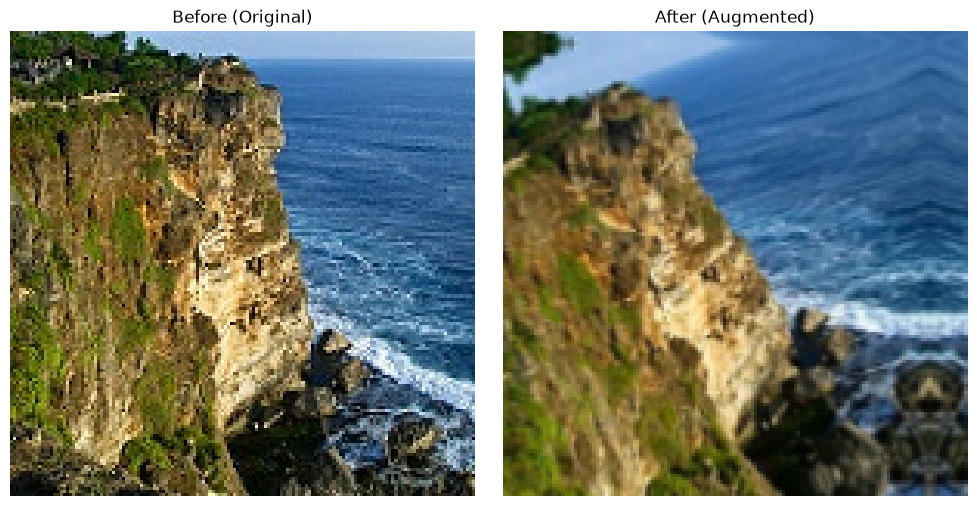

In [15]:
import matplotlib.pyplot as plt

for images , label in train_ds.take(1):

    original_img = images[0]

    augmented_img = data_augmentation(images[0:1])


    plt.figure(figsize=(10, 5))
  
    plt.subplot(1, 2, 1)
    plt.imshow(original_img.numpy().astype("uint8"))
    plt.title("Before (Original)")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(augmented_img[0].numpy().astype("uint8"))
    plt.title("After (Augmented)")
    plt.axis("off")
    plt.tight_layout()
    plt.show()
    break

**Prevents overfitting**: Stops the model from memorizing exact pixel coordinates.

**Improves generalization**: Exposes the CNN to realistic variations (tilted angles, zoomed views, flipped perspectives) so it recognizes objects in unseen, real-world photos.